Found 18 valid wrfsfc_d03 NetCDF files.
Skipped non-NetCDF/non-timestamp wrfsfc_d03 files:
   wrfsfc_d03_variable_list.csv
Reading XLAT/XLONG from: wrfinput_d03
Grid size: south_north=936, west_east=924
KBTR  Baton Rouge, LA   : requested=(30.537, -91.147), grid=(30.539, -91.146), iy=370, ix=313
KMSY  New Orleans, LA   : requested=(29.998, -90.278), grid=(29.998, -90.273), iy=309, ix=397
KMEI  Meridian, MS      : requested=(32.335, -88.751), grid=(32.335, -88.748), iy=571, ix=541
KGZH  Evergreen, AL     : requested=(31.417, -87.050), grid=(31.413, -87.053), iy=472, ix=704
KTCL  Tuscaloosa, AL    : requested=(33.212, -87.616), grid=(33.213, -87.616), iy=671, ix=645
KMGM  Montgomery, AL    : requested=(32.300, -86.407), grid=(32.299, -86.403), iy=573, ix=762
KBHM  Birmingham, AL    : requested=(33.565, -86.745), grid=(33.567, -86.742), iy=713, ix=725
KMSL  Muscle Shoals, AL : requested=(34.744, -87.600), grid=(34.740, -87.599), iy=841, ix=642
KANB  Anniston, AL      : requested=(33.590, 

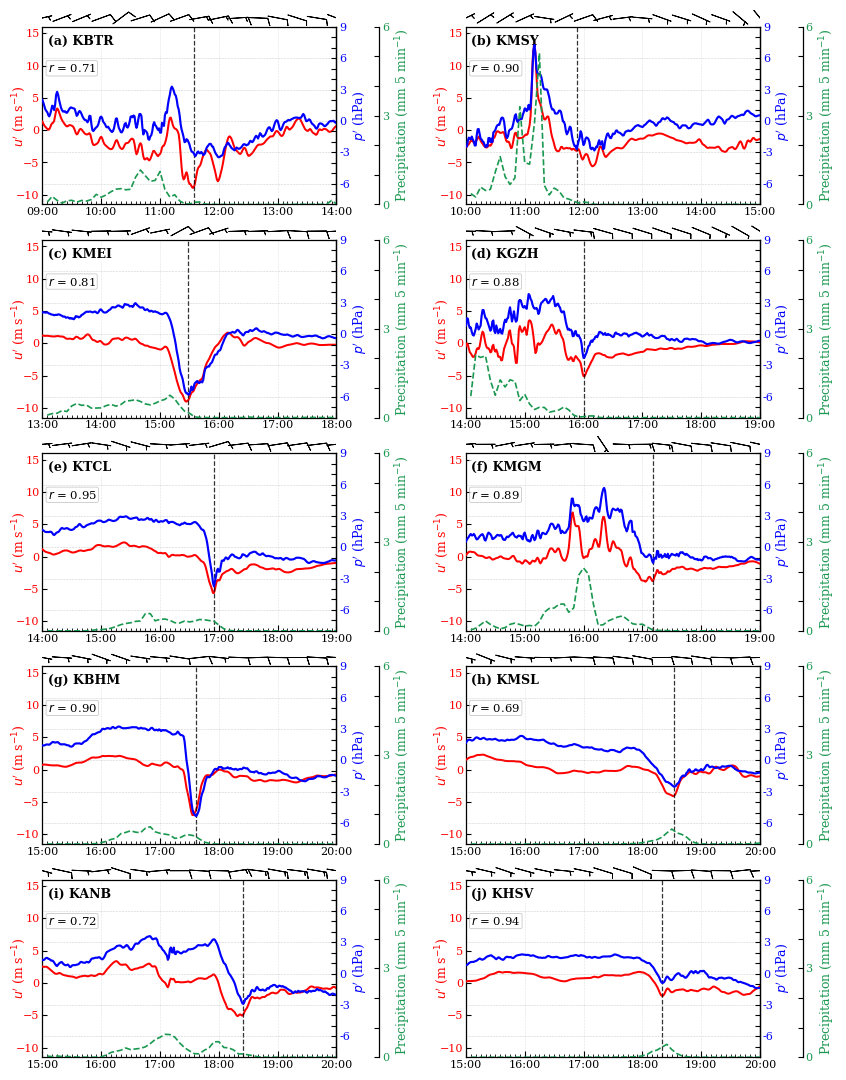


Saved:
Wave-covariance-WRF-10-stations-boxed-with-wind-barbs.png
Wave-covariance-WRF-10-stations-boxed-with-wind-barbs.pdf


In [1]:
import re
import math
import logging
import numpy as np
import netCDF4 as nc
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from datetime import datetime
from pathlib import Path


# fontTools chatters at INFO level.
logging.getLogger("fontTools").setLevel(logging.ERROR)


dataDir = Path(
    "/glade/derecho/scratch/rbhandari/"
    "AL-CNTRL-MP8-new/wrfv4.7.1/test/em_real"
)


# Background state is an 8 h running mean of the 1-min output.
ROLLING_HOURS = 8
ROLLING_WINDOW = ROLLING_HOURS * 60


# One barb every 20 minutes.
BARB_INTERVAL_MINUTES = 20

# Barb increments, m s^-1.
BARB_HALF = 5
BARB_FULL = 10
BARB_FLAG = 50


u_color = "#FF0000"      # u' = red
p_color = "#0000FF"      # p' = blue
rain_color = "#1A9850"   # precipitation = green


# Axis and label placement.
Y_LABEL_MIDDLE = 0.50

# u' on the left.
U_LABEL_X = -0.050

# p' label.
P_LABEL_X = 1.050

# Rain axis, pushed outside p'.
RAIN_AXIS_OFFSET = 1.145

# Rain label.
RAIN_LABEL_X = 1.195


# p' axis fixed at -8 to 9 hPa, ticks every 1 hPa, labels every 3.
P_AXIS_MIN = -8.0
P_AXIS_MAX = 9.0

p_ticks = np.arange(
    P_AXIS_MIN,
    P_AXIS_MAX + 1.0,
    1.0
)

p_tick_labels = [
    f"{int(value)}"
    if np.isclose(value % 3.0, 0.0)
    else ""
    for value in p_ticks
]

# Dashed reference lines at these p' values only.
p_grid_levels = np.array(
    [-6.0, -3.0, 0.0, 3.0, 6.0]
)


# Rain axis fixed at 0 to 6 mm, ticks every 1 mm, labels every 3.
RAIN_AXIS_MIN = 0.0
RAIN_AXIS_MAX = 6.0

rain_ticks = np.arange(
    RAIN_AXIS_MIN,
    RAIN_AXIS_MAX + 1.0,
    1.0
)

rain_tick_labels = [
    f"{int(value)}"
    if np.isclose(value % 3.0, 0.0)
    else ""
    for value in rain_ticks
]


# Plot defaults.
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9.0,
    "axes.labelsize": 9.0,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0,
    "legend.fontsize": 9.0,
    "axes.linewidth": 0.90,
    "axes.edgecolor": "black",
    "xtick.major.width": 0.80,
    "ytick.major.width": 0.80,
    "xtick.minor.width": 0.60,
    "ytick.minor.width": 0.60,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# Collect the wrfsfc files, ignoring anything without a proper timestamp.
wrfsfc_pattern = re.compile(
    r"^wrfsfc_d03_\d{4}-\d{2}-\d{2}_\d{2}:\d{2}:\d{2}$"
)

sfc_files = sorted(
    fp for fp in dataDir.iterdir()
    if fp.is_file() and wrfsfc_pattern.match(fp.name)
)

if not sfc_files:
    raise FileNotFoundError(
        "No valid wrfsfc_d03 timestamp NetCDF files found."
    )

print(
    f"Found {len(sfc_files)} valid wrfsfc_d03 NetCDF files."
)


skipped_files = sorted(
    fp.name
    for fp in dataDir.glob("wrfsfc_d03_*")
    if fp.is_file()
    and not wrfsfc_pattern.match(fp.name)
)

if skipped_files:
    print(
        "Skipped non-NetCDF/non-timestamp wrfsfc_d03 files:"
    )

    for fname in skipped_files:
        print("  ", fname)


# XLAT/XLONG from whichever file carries them.
latlon_candidates = [
    dataDir / "wrfinput_d03",
    *sorted(dataDir.glob("wrfout_d03_*"))
]

latlon_file = None

for candidate_file in latlon_candidates:

    if candidate_file.exists():
        latlon_file = candidate_file
        break


if latlon_file is None:
    raise FileNotFoundError(
        "Could not find wrfinput_d03 or wrfout_d03 "
        "file for XLAT/XLONG."
    )


print(
    f"Reading XLAT/XLONG from: {latlon_file.name}"
)

with nc.Dataset(latlon_file, "r") as dataset:

    lat = np.squeeze(
        dataset.variables["XLAT"][:]
    )

    lon = np.squeeze(
        dataset.variables["XLONG"][:]
    )


ny, nx = lat.shape

print(
    f"Grid size: south_north={ny}, west_east={nx}"
)


# Stations, each with its own plotting window.
stations = {

    "KBTR": {
        "name": "Baton Rouge, LA",
        "lat": 30.5370,
        "lon": -91.1470,
        "label": "KBTR",
        "start": "1998-02-22 09:00:00",
        "end":   "1998-02-22 14:00:00"
    },

    "KMSY": {
        "name": "New Orleans, LA",
        "lat": 29.9980,
        "lon": -90.2780,
        "label": "KMSY",
        "start": "1998-02-22 10:00:00",
        "end":   "1998-02-22 15:00:00"
    },

    "KMEI": {
        "name": "Meridian, MS",
        "lat": 32.3350,
        "lon": -88.7510,
        "label": "KMEI",
        "start": "1998-02-22 13:00:00",
        "end":   "1998-02-22 18:00:00"
    },

    "KGZH": {
        "name": "Evergreen, AL",
        "lat": 31.4170,
        "lon": -87.0500,
        "label": "KGZH",
        "start": "1998-02-22 14:00:00",
        "end":   "1998-02-22 19:00:00"
    },

    "KTCL": {
        "name": "Tuscaloosa, AL",
        "lat": 33.2120,
        "lon": -87.6160,
        "label": "KTCL",
        "start": "1998-02-22 14:00:00",
        "end":   "1998-02-22 19:00:00"
    },

    "KMGM": {
        "name": "Montgomery, AL",
        "lat": 32.3000,
        "lon": -86.4070,
        "label": "KMGM",
        "start": "1998-02-22 14:00:00",
        "end":   "1998-02-22 19:00:00"
    },

    "KBHM": {
        "name": "Birmingham, AL",
        "lat": 33.5650,
        "lon": -86.7450,
        "label": "KBHM",
        "start": "1998-02-22 15:00:00",
        "end":   "1998-02-22 20:00:00"
    },

    "KMSL": {
        "name": "Muscle Shoals, AL",
        "lat": 34.7440,
        "lon": -87.6000,
        "label": "KMSL",
        "start": "1998-02-22 15:00:00",
        "end":   "1998-02-22 20:00:00"
    },

    "KANB": {
        "name": "Anniston, AL",
        "lat": 33.5900,
        "lon": -85.8480,
        "label": "KANB",
        "start": "1998-02-22 15:00:00",
        "end":   "1998-02-22 20:00:00"
    },

    "KHSV": {
        "name": "Huntsville, AL",
        "lat": 34.6440,
        "lon": -86.7860,
        "label": "KHSV",
        "start": "1998-02-22 15:00:00",
        "end":   "1998-02-22 20:00:00"
    }
}


# Wave propagation direction, the same at every station.
for sid in stations:

    stations[sid]["theta_deg"] = 220.0

    stations[sid]["start"] = pd.Timestamp(
        stations[sid]["start"]
    )

    stations[sid]["end"] = pd.Timestamp(
        stations[sid]["end"]
    )


# Reference time per station. It places the dashed vertical line and
# centers the correlation window. Stations left out of this dict fall
# back to their own p' minimum.
correlation_reference_times = {
    "KBTR": pd.Timestamp("1998-02-22 11:35:00"),
    "KMSY": pd.Timestamp("1998-02-22 11:53:00"),
    "KHSV": pd.Timestamp("1998-02-22 18:20:00")
}


def nearest_grid_point(
    lat2d,
    lon2d,
    lat0,
    lon0
):
    """
    Find the nearest WRF grid point to a station using
    great-circle distance.
    """

    latr = np.radians(lat2d)
    lonr = np.radians(lon2d)

    lat0r = np.radians(lat0)
    lon0r = np.radians(lon0)

    dlat = latr - lat0r
    dlon = lonr - lon0r

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(latr)
        * np.cos(lat0r)
        * np.sin(dlon / 2.0) ** 2
    )

    iy, ix = np.unravel_index(
        np.nanargmin(a),
        a.shape
    )

    return iy, ix


def decode_wrf_times(times_char):
    """
    Decode the WRF Times character array.
    """

    output_times = []

    for row in times_char:

        try:

            time_string = (
                b"".join(row)
                .decode("utf-8")
            )

        except TypeError:

            time_string = "".join(
                value.decode("utf-8")
                if isinstance(value, bytes)
                else str(value)
                for value in row
            )

        output_times.append(
            datetime.strptime(
                time_string,
                "%Y-%m-%d_%H:%M:%S"
            )
        )

    return output_times


def to_float_array(array):
    """
    Masked NetCDF array to a plain float array.
    """

    return np.asarray(
        np.ma.filled(
            array,
            np.nan
        ),
        dtype=float
    )


def rolling_mean_1d(
    values,
    window
):
    """
    Centered rolling mean.
    """

    return (
        pd.Series(values)
        .rolling(
            window=window,
            center=True,
            min_periods=1
        )
        .mean()
        .to_numpy()
    )


def calculate_5min_rain(
    times,
    rain_increment
):
    """
    1-min increments to nonoverlapping 5-min accumulations.

    Each value is the rain that fell in the preceding five minutes.
    """

    rain_series = pd.Series(
        np.asarray(
            rain_increment,
            dtype=float
        ),
        index=pd.DatetimeIndex(times)
    )

    rain_series = (
        rain_series
        .groupby(level=0)
        .last()
        .sort_index()
    )

    rain_5min = rain_series.resample(
        "5min",
        label="right",
        closed="right"
    ).sum(
        min_count=1
    )

    return (
        rain_5min.index,
        rain_5min.to_numpy(dtype=float)
    )


def padded_limits(
    vmin,
    vmax,
    pad_fraction=0.10,
    min_span=1.0
):
    """
    Add padding to common plotting limits.
    """

    if (
        not np.isfinite(vmin)
        or not np.isfinite(vmax)
    ):
        return -1.0, 1.0

    span = vmax - vmin

    if span <= 0:

        center = 0.5 * (
            vmin + vmax
        )

        half = 0.5 * min_span

        return (
            center - half,
            center + half
        )

    if span < min_span:

        center = 0.5 * (
            vmin + vmax
        )

        half = 0.5 * min_span

        return (
            center - half,
            center + half
        )

    padding = pad_fraction * span

    return (
        vmin - padding,
        vmax + padding
    )


def round_limits(
    vmin,
    vmax,
    step
):
    """
    Round plotting limits outward to the specified interval.
    """

    rounded_min = (
        np.floor(vmin / step)
        * step
    )

    rounded_max = (
        np.ceil(vmax / step)
        * step
    )

    return (
        rounded_min,
        rounded_max
    )


def set_black_subplot_box(ax):
    """
    Black box around a subplot.
    """

    for side in [
        "left",
        "right",
        "bottom",
        "top"
    ]:

        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(0.90)


def configure_right_twin_axis(ax):
    """
    Keep only the right spine visible on a twinned axis.
    """

    ax.spines["right"].set_visible(True)
    ax.spines["right"].set_color("black")
    ax.spines["right"].set_linewidth(0.90)

    ax.spines["left"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_visible(False)


def select_wind_barbs(
    times,
    u10,
    v10,
    interval_minutes=30
):
    """
    Wind vectors on exact clock minutes: HH:00 and HH:30 for
    interval_minutes=30.
    """

    times = pd.DatetimeIndex(times)

    valid = (
        np.isfinite(u10)
        & np.isfinite(v10)
    )

    interval_mask = (
        (times.minute % interval_minutes == 0)
        & (times.second == 0)
    )

    selected = (
        valid
        & interval_mask
    )

    if not np.any(selected):

        approximate_step = max(
            1,
            int(interval_minutes)
        )

        selected_indices = np.arange(
            0,
            len(times),
            approximate_step
        )

        selected = np.zeros(
            len(times),
            dtype=bool
        )

        selected[selected_indices] = True

        selected = (
            selected
            & valid
        )

    return (
        times[selected],
        np.asarray(u10)[selected],
        np.asarray(v10)[selected]
    )


# Nearest grid point for each station.
station_cache = {}

for sid, info in stations.items():

    iy, ix = nearest_grid_point(
        lat,
        lon,
        info["lat"],
        info["lon"]
    )

    station_cache[sid] = {
        "iy": iy,
        "ix": ix,
        "theta_rad": np.radians(
            info["theta_deg"]
        ),
        "times": [],
        "u10": [],
        "v10": [],
        "psfc": [],
        "rainc": [],
        "rainnc": []
    }

    print(
        f"{sid:5s} "
        f"{info['name']:18s}: "
        f"requested="
        f"({info['lat']:.3f}, {info['lon']:.3f}), "
        f"grid="
        f"({lat[iy, ix]:.3f}, {lon[iy, ix]:.3f}), "
        f"iy={iy}, ix={ix}"
    )


# Read the surface fields.
for file_path in sfc_files:

    print(
        f"Reading {file_path.name}"
    )

    with nc.Dataset(
        file_path,
        "r"
    ) as dataset:

        file_times = decode_wrf_times(
            dataset.variables["Times"][:]
        )

        for sid in stations:

            iy = station_cache[sid]["iy"]
            ix = station_cache[sid]["ix"]

            station_cache[sid]["times"].extend(
                file_times
            )

            station_cache[sid]["u10"].append(
                to_float_array(
                    dataset.variables[
                        "U10"
                    ][:, iy, ix]
                )
            )

            station_cache[sid]["v10"].append(
                to_float_array(
                    dataset.variables[
                        "V10"
                    ][:, iy, ix]
                )
            )

            station_cache[sid]["psfc"].append(
                to_float_array(
                    dataset.variables[
                        "PSFC"
                    ][:, iy, ix]
                )
            )

            station_cache[sid]["rainc"].append(
                to_float_array(
                    dataset.variables[
                        "RAINC"
                    ][:, iy, ix]
                )
            )

            station_cache[sid]["rainnc"].append(
                to_float_array(
                    dataset.variables[
                        "RAINNC"
                    ][:, iy, ix]
                )
            )


# Concatenate the per-file chunks and sort by time.
for sid in stations:

    meta = station_cache[sid]

    meta["times"] = pd.to_datetime(
        meta["times"]
    )

    meta["u10"] = np.concatenate(
        meta["u10"]
    )

    meta["v10"] = np.concatenate(
        meta["v10"]
    )

    meta["psfc"] = np.concatenate(
        meta["psfc"]
    )

    meta["rainc"] = np.concatenate(
        meta["rainc"]
    )

    meta["rainnc"] = np.concatenate(
        meta["rainnc"]
    )

    sorting_order = np.argsort(
        meta["times"]
    )

    meta["times"] = (
        meta["times"][sorting_order]
    )

    meta["u10"] = (
        meta["u10"][sorting_order]
    )

    meta["v10"] = (
        meta["v10"][sorting_order]
    )

    meta["psfc"] = (
        meta["psfc"][sorting_order]
    )

    meta["rainc"] = (
        meta["rainc"][sorting_order]
    )

    meta["rainnc"] = (
        meta["rainnc"][sorting_order]
    )


first_station = list(
    stations.keys()
)[0]

test_times = station_cache[
    first_station
]["times"]

dt_minutes = (
    np.diff(test_times.values)
    .astype("timedelta64[s]")
    .astype(float)
    / 60.0
)


print("\nTime summary from wrfsfc:")

print(
    "Number of 1-min records:",
    len(test_times)
)

print(
    "First time:",
    test_times[0]
)

print(
    "Last time:",
    test_times[-1]
)

print(
    "Median interval:",
    np.nanmedian(dt_minutes),
    "minutes"
)

print(
    "Rolling mean window:",
    ROLLING_WINDOW,
    "points =",
    ROLLING_HOURS,
    "hours"
)


# Rain increments, then 5-min accumulations.
for sid in stations:

    meta = station_cache[sid]

    rain_total = (
        meta["rainc"]
        + meta["rainnc"]
    )

    rain_increment = np.diff(
        rain_total,
        prepend=rain_total[0]
    )

    rain_increment[
        rain_increment < 0
    ] = 0.0

    meta["rain_1min"] = (
        rain_increment
    )

    (
        meta["rain_5min_times"],
        meta["rain_5min"]
    ) = calculate_5min_rain(
        meta["times"],
        rain_increment
    )


# Project the wind onto the wave direction, then remove the running mean.
for sid in stations:

    meta = station_cache[sid]

    theta = meta["theta_rad"]

    wave_relative_wind = (
        -meta["u10"]
        * np.sin(theta)
        - meta["v10"]
        * np.cos(theta)
    )

    wind_smooth = rolling_mean_1d(
        wave_relative_wind,
        ROLLING_WINDOW
    )

    meta["wind_prime"] = (
        wave_relative_wind
        - wind_smooth
    )


# Pressure perturbation, Pa to hPa.
for sid in stations:

    meta = station_cache[sid]

    psfc_smooth = rolling_mean_1d(
        meta["psfc"],
        ROLLING_WINDOW
    )

    meta["psfc_prime"] = (
        meta["psfc"]
        - psfc_smooth
    ) / 100.0


# One u' range shared by every panel.
u_global_min = np.inf
u_global_max = -np.inf


for sid, info in stations.items():

    meta = station_cache[sid]

    data_mask = (
        (meta["times"] >= info["start"])
        & (meta["times"] <= info["end"])
    )

    if not data_mask.any():
        continue

    station_uprime = (
        meta["wind_prime"][data_mask]
    )

    if np.isfinite(
        station_uprime
    ).any():

        u_global_min = min(
            u_global_min,
            np.nanmin(station_uprime)
        )

        u_global_max = max(
            u_global_max,
            np.nanmax(station_uprime)
        )


u_global_min, u_global_max = padded_limits(
    u_global_min,
    u_global_max,
    pad_fraction=0.10,
    min_span=2.0
)

u_global_min, u_global_max = round_limits(
    u_global_min,
    u_global_max,
    0.5
)


p_global_min = P_AXIS_MIN
p_global_max = P_AXIS_MAX

rain_global_min = RAIN_AXIS_MIN
rain_global_max = RAIN_AXIS_MAX


print("\nCommon plotting limits:")

print(
    f"u′ axis: "
    f"{u_global_min:.2f} to "
    f"{u_global_max:.2f} m s^-1"
)

print(
    f"p′ axis: "
    f"{p_global_min:.2f} to "
    f"{p_global_max:.2f} hPa"
)

print(
    f"5-min rain axis: "
    f"{rain_global_min:.2f} to "
    f"{rain_global_max:.2f} mm"
)


def plot_station_panel(
    ax1,
    sid,
    info,
    panel_letter
):
    """
    Plot one WRF meteogram panel.
    """

    meta = station_cache[sid]

    times = meta["times"]

    data_mask = (
        (times >= info["start"])
        & (times <= info["end"])
    )

    if not data_mask.any():

        print(
            f"WARNING: No data found for {sid} "
            f"between {info['start']} and {info['end']}."
        )

        ax1.set_visible(False)

        return


    # Subset to this station's window.
    station_times = times[data_mask]

    u10_station = (
        meta["u10"][data_mask]
    )

    v10_station = (
        meta["v10"][data_mask]
    )

    wind_prime_station = (
        meta["wind_prime"][data_mask]
    )

    pressure_prime_station = (
        meta["psfc_prime"][data_mask]
    )


    # 5-min rainfall.
    rain_times = (
        meta["rain_5min_times"]
    )

    rain_mask = (
        (rain_times > info["start"])
        & (rain_times <= info["end"])
    )

    rain_times_station = (
        rain_times[rain_mask]
    )

    rain_station = (
        meta["rain_5min"][rain_mask]
    )


    # p' minimum, which is the fallback reference time.
    valid_pressure = np.isfinite(
        pressure_prime_station
    )

    if valid_pressure.any():

        minimum_index = np.nanargmin(
            pressure_prime_station
        )

        minimum_time = (
            station_times[minimum_index]
        )

    else:

        minimum_time = (
            info["start"]
            + (
                info["end"]
                - info["start"]
            ) / 2
        )


    # Take the override where one is set, otherwise the p' minimum.
    if sid in correlation_reference_times:

        reference_time = (
            correlation_reference_times[sid]
        )

    else:

        reference_time = minimum_time


    # Correlate u' against p' over 1.5 h either side of that time.
    correlation_start = (
        reference_time
        - pd.Timedelta(hours=1.5)
    )

    correlation_end = (
        reference_time
        + pd.Timedelta(hours=1.5)
    )

    correlation_mask = (
        (station_times >= correlation_start)
        & (station_times <= correlation_end)
    )

    u_corr = (
        wind_prime_station[
            correlation_mask
        ]
    )

    p_corr = (
        pressure_prime_station[
            correlation_mask
        ]
    )

    valid_corr = (
        np.isfinite(u_corr)
        & np.isfinite(p_corr)
    )

    if valid_corr.sum() >= 2:

        correlation_value = np.corrcoef(
            u_corr[valid_corr],
            p_corr[valid_corr]
        )[0, 1]

    else:

        correlation_value = np.nan


    # u' on the left axis.
    ax1.plot(
        station_times,
        wind_prime_station,
        color=u_color,
        linewidth=1.45,
        zorder=6
    )

    ax1.set_ylabel(
        r"$u'$ (m s$^{-1}$)",
        color=u_color,
        labelpad=1
    )

    ax1.yaxis.set_label_coords(
        U_LABEL_X,
        Y_LABEL_MIDDLE
    )

    ax1.tick_params(
        axis="y",
        which="both",
        color="black",
        labelcolor=u_color,
        pad=2
    )

    ax1.set_ylim(
        u_global_min,
        u_global_max
    )

    ax1.set_xlim(
        info["start"],
        info["end"]
    )

    set_black_subplot_box(
        ax1
    )


    # p' on the first right axis.
    ax2 = ax1.twinx()

    ax2.plot(
        station_times,
        pressure_prime_station,
        color=p_color,
        linewidth=1.55,
        zorder=7
    )

    ax2.set_ylabel(
        r"$p'$ (hPa)",
        color=p_color,
        labelpad=0
    )

    ax2.yaxis.set_label_coords(
        P_LABEL_X,
        Y_LABEL_MIDDLE
    )

    ax2.tick_params(
        axis="y",
        which="both",
        color="black",
        labelcolor=p_color,
        pad=2
    )

    ax2.set_ylim(
        p_global_min,
        p_global_max
    )

    ax2.set_yticks(
        p_ticks
    )

    ax2.set_yticklabels(
        p_tick_labels
    )

    ax2.set_xlim(
        info["start"],
        info["end"]
    )

    configure_right_twin_axis(
        ax2
    )


    # Horizontal reference lines.
    for pressure_level in p_grid_levels:

        ax2.axhline(
            pressure_level,
            color="gray",
            linewidth=0.40,
            linestyle="--",
            alpha=0.38,
            zorder=1
        )


    # Rain on an outer right axis, offset clear of p'.
    ax3 = ax1.twinx()

    ax3.spines["right"].set_position(
        ("axes", RAIN_AXIS_OFFSET)
    )

    if len(
        rain_times_station
    ) > 0:

        ax3.plot(
            rain_times_station,
            rain_station,
            color=rain_color,
            linestyle="--",
            linewidth=1.20,
            clip_on=True,
            zorder=8
        )

    ax3.set_ylabel(
        "Precipitation (mm 5 min$^{-1}$)",
        color=rain_color,
        labelpad=0
    )

    ax3.yaxis.set_label_coords(
        RAIN_LABEL_X,
        Y_LABEL_MIDDLE
    )

    ax3.tick_params(
        axis="y",
        which="both",
        color="black",
        labelcolor=rain_color,
        pad=2
    )

    ax3.set_ylim(
        rain_global_min,
        rain_global_max
    )

    ax3.set_yticks(
        rain_ticks
    )

    ax3.set_yticklabels(
        rain_tick_labels
    )

    ax3.set_xlim(
        info["start"],
        info["end"]
    )

    configure_right_twin_axis(
        ax3
    )


    # Mark the reference time.
    ax1.axvline(
        reference_time,
        color="black",
        linestyle="--",
        linewidth=0.90,
        alpha=0.80,
        zorder=9
    )


    # Hourly major ticks, 5-min minor ticks.
    ax1.xaxis.set_major_locator(
        mdates.HourLocator(
            interval=1
        )
    )

    ax1.xaxis.set_major_formatter(
        mdates.DateFormatter(
            "%H:%M"
        )
    )

    ax1.xaxis.set_minor_locator(
        mdates.MinuteLocator(
            interval=5
        )
    )

    ax1.tick_params(
        axis="x",
        which="major",
        length=4.0,
        width=0.80,
        color="black",
        labelcolor="black",
        pad=2
    )

    ax1.tick_params(
        axis="x",
        which="minor",
        length=2.0,
        width=0.60,
        color="black"
    )


    # Gridlines on the hourly ticks only.
    ax1.grid(
        True,
        which="major",
        axis="x",
        linestyle="--",
        linewidth=0.40,
        alpha=0.38,
        zorder=0
    )

    ax1.grid(
        False,
        which="minor",
        axis="x"
    )

    set_black_subplot_box(
        ax1
    )


    # Panel tag.
    ax1.text(
        0.018,
        0.955,
        f"({panel_letter}) {sid}",
        transform=ax1.transAxes,
        ha="left",
        va="top",
        fontsize=9.0,
        fontweight="bold",
        bbox={
            "boxstyle": "round,pad=0.16",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75
        },
        zorder=20
    )


    # Correlation, just under the tag.
    if np.isfinite(
        correlation_value
    ):

        correlation_text = (
            rf"$r$ = "
            rf"{correlation_value:.2f}"
        )

    else:

        correlation_text = (
            r"$r$ = NaN"
        )


    ax1.text(
        0.018,
        0.800,
        correlation_text,
        transform=ax1.transAxes,
        ha="left",
        va="top",
        fontsize=8.4,
        bbox={
            "boxstyle": "round,pad=0.14",
            "facecolor": "white",
            "edgecolor": "0.65",
            "linewidth": 0.45,
            "alpha": 0.80
        },
        zorder=20
    )


    # Barbs in a thin strip above the panel.
    barb_times, barb_u, barb_v = select_wind_barbs(
        station_times,
        u10_station,
        v10_station,
        interval_minutes=BARB_INTERVAL_MINUTES
    )

    ax_barb = ax1.inset_axes(
        [
            0.0,
            1.005,
            1.0,
            0.090
        ],
        transform=ax1.transAxes
    )

    ax_barb.set_xlim(
        ax1.get_xlim()
    )

    ax_barb.set_ylim(
        0.0,
        1.0
    )

    if len(barb_times) > 0:

        barb_x = mdates.date2num(
            barb_times.to_pydatetime()
        )

        ax_barb.barbs(
            barb_x,
            np.full(
                len(barb_times),
                0.5
            ),
            barb_u,
            barb_v,
            length=5.3,
            linewidth=0.68,
            color="black",
            barbcolor="black",
            flagcolor="black",
            barb_increments={
                "half": BARB_HALF,
                "full": BARB_FULL,
                "flag": BARB_FLAG
            },
            pivot="middle",
            zorder=10
        )

    ax_barb.set_yticks([])
    ax_barb.set_xticks([])
    ax_barb.set_xticklabels([])

    ax_barb.tick_params(
        axis="both",
        which="both",
        left=False,
        right=False,
        top=False,
        bottom=False,
        labelleft=False,
        labelright=False,
        labeltop=False,
        labelbottom=False
    )

    for spine in ax_barb.spines.values():
        spine.set_visible(False)


    if np.isfinite(
        correlation_value
    ):

        r_print = (
            f"{correlation_value:.3f}"
        )

    else:

        r_print = "NaN"


    print(
        f"({panel_letter}) {sid} - {info['name']}: "
        f"plot window = "
        f"{info['start']:%H:%M}–"
        f"{info['end']:%H:%M} UTC, "
        f"minimum p' at "
        f"{minimum_time:%H:%M} UTC, "
        f"reference time = "
        f"{reference_time:%H:%M} UTC, "
        f"correlation window = "
        f"{correlation_start:%H:%M}–"
        f"{correlation_end:%H:%M} UTC, "
        f"r = {r_print}"
    )


# Lay the stations out in two columns.
station_items = list(
    stations.items()
)

n_stations = len(
    station_items
)

ncols = 2

nrows = math.ceil(
    n_stations / ncols
)


# Sized to fit one page.
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9.2, 11.2),
    squeeze=False
)

axes_flat = axes.flatten()

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)


print(
    "\n=== Correlation between u′ and p′ in a ±1.5-h window "
    "around the station-specific reference time ==="
)


for panel_index, (
    sid,
    info
) in enumerate(
    station_items
):

    plot_station_panel(
        axes_flat[panel_index],
        sid,
        info,
        panel_letters[panel_index]
    )


for unused_ax in axes_flat[n_stations:]:

    unused_ax.set_visible(False)


# Tight vertically; wide horizontally to clear the three y axes.
fig.subplots_adjust(
    left=0.075,
    right=0.855,
    top=0.975,
    bottom=0.055,
    hspace=0.200,
    wspace=0.440
)


output_png = (
    "Wave-covariance-WRF-10-stations-"
    "boxed-with-wind-barbs.png"
)

output_pdf = (
    "Wave-covariance-WRF-10-stations-"
    "boxed-with-wind-barbs.pdf"
)


fig.savefig(
    output_png,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.030
)

fig.savefig(
    output_pdf,
    bbox_inches="tight",
    pad_inches=0.030
)

plt.show()


print("\nSaved:")
print(output_png)
print(output_pdf)